# EuroSAT (RGB) — dataset check
CPS 4841 course project, dataset selection step.

This notebook downloads EuroSAT RGB, counts images per class, plots the class distribution, shows sample images with their labels, and verifies the annotations (folder-name labels). It runs top to bottom in a fresh Google Colab runtime.

Dataset: Helber et al., *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, IEEE JSTARS 2019. Download: https://zenodo.org/records/7711810 (MIT license).

In [1]:
# 1. Download and unzip (about 90 MB). Skipped if the data is already present.
import os, urllib.request, zipfile
URL = 'https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip'
DATA_DIR = 'data'
ROOT = os.path.join(DATA_DIR, 'EuroSAT_RGB')
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.isdir(ROOT):
    zip_path = os.path.join(DATA_DIR, 'EuroSAT_RGB.zip')
    urllib.request.urlretrieve(URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)
print('Dataset folder:', ROOT)
print('Class folders:', sorted(os.listdir(ROOT)))

Dataset folder: data/EuroSAT_RGB
Class folders: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [2]:
# 2. Count images per class and check every file opens as a 64x64 RGB image
import glob, collections
import numpy as np, pandas as pd
from PIL import Image

CLASSES = sorted(d for d in os.listdir(ROOT) if os.path.isdir(os.path.join(ROOT, d)))
records, bad, shapes = [], [], collections.Counter()
for label_id, cls in enumerate(CLASSES):
    for path in sorted(glob.glob(os.path.join(ROOT, cls, '*.jpg'))):
        try:
            with Image.open(path) as im:
                shapes[(im.size, im.mode)] += 1
            records.append({'path': path, 'label': cls, 'label_id': label_id})
        except Exception as e:
            bad.append((path, str(e)))
df = pd.DataFrame(records)
print('Number of classes:', len(CLASSES))
print('Total images     :', len(df))
print('Unreadable files :', len(bad))
print('Image size / mode:', dict(shapes))
counts = df['label'].value_counts().reindex(CLASSES)
table = pd.DataFrame({'images': counts, 'percent': (100 * counts / counts.sum()).round(2)})
table

Number of classes: 10
Total images     : 27000
Unreadable files : 0
Image size / mode: {((64, 64), 'RGB'): 27000}


,images,percent
label,,
AnnualCrop,3000,11.11
Forest,3000,11.11
HerbaceousVegetation,3000,11.11
Highway,2500,9.26
Industrial,2500,9.26
Pasture,2000,7.41
PermanentCrop,2500,9.26
Residential,3000,11.11
River,2500,9.26


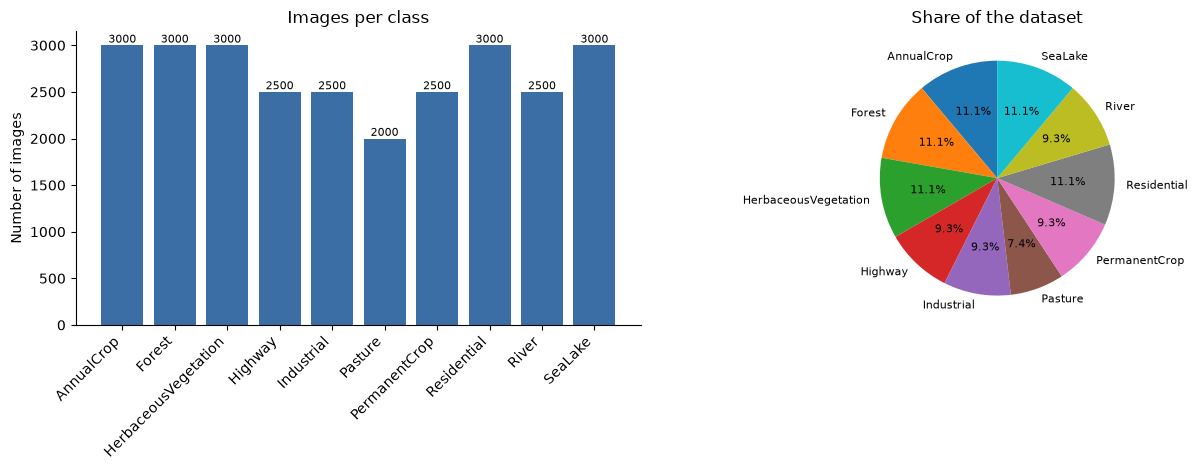

In [3]:
# 3. Class distribution: bar chart and pie chart
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bars = axes[0].bar(CLASSES, counts.values, color='#3b6ea5')
axes[0].bar_label(bars, fontsize=8)
axes[0].set_ylabel('Number of images'); axes[0].set_title('Images per class')
axes[0].tick_params(axis='x', rotation=45)
for t in axes[0].get_xticklabels(): t.set_ha('right')
axes[0].spines[['top', 'right']].set_visible(False)
axes[1].pie(counts.values, labels=CLASSES, autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 8}, colors=plt.cm.tab10.colors)
axes[1].set_title('Share of the dataset')
plt.tight_layout(); plt.savefig('figures/class_distribution.png', dpi=200); plt.show()

In [4]:
# 4. Planned split: stratified 70 / 15 / 15 (train / val / test), fixed seed
# EuroSAT has no official split, so we make one and keep the class ratios equal in every part.
rng = np.random.default_rng(42)
split = np.empty(len(df), dtype=object)
for cls in CLASSES:
    idx = rng.permutation(df.index[df['label'] == cls].to_numpy())
    n_tr, n_va = int(0.70 * len(idx)), int(0.15 * len(idx))
    split[idx[:n_tr]] = 'train'; split[idx[n_tr:n_tr + n_va]] = 'val'; split[idx[n_tr + n_va:]] = 'test'
df['split'] = split
split_table = pd.crosstab(df['label'], df['split'], margins=True, margins_name='Total')[['train', 'val', 'test', 'Total']]
df[['path', 'label', 'label_id', 'split']].to_csv('splits.csv', index=False)
split_table

split,train,val,test,Total
label,,,,
AnnualCrop,2100,450,450,3000
Forest,2100,450,450,3000
HerbaceousVegetation,2100,450,450,3000
Highway,1750,375,375,2500
Industrial,1750,375,375,2500
Pasture,1400,300,300,2000
PermanentCrop,1750,375,375,2500
Residential,2100,450,450,3000
River,1750,375,375,2500


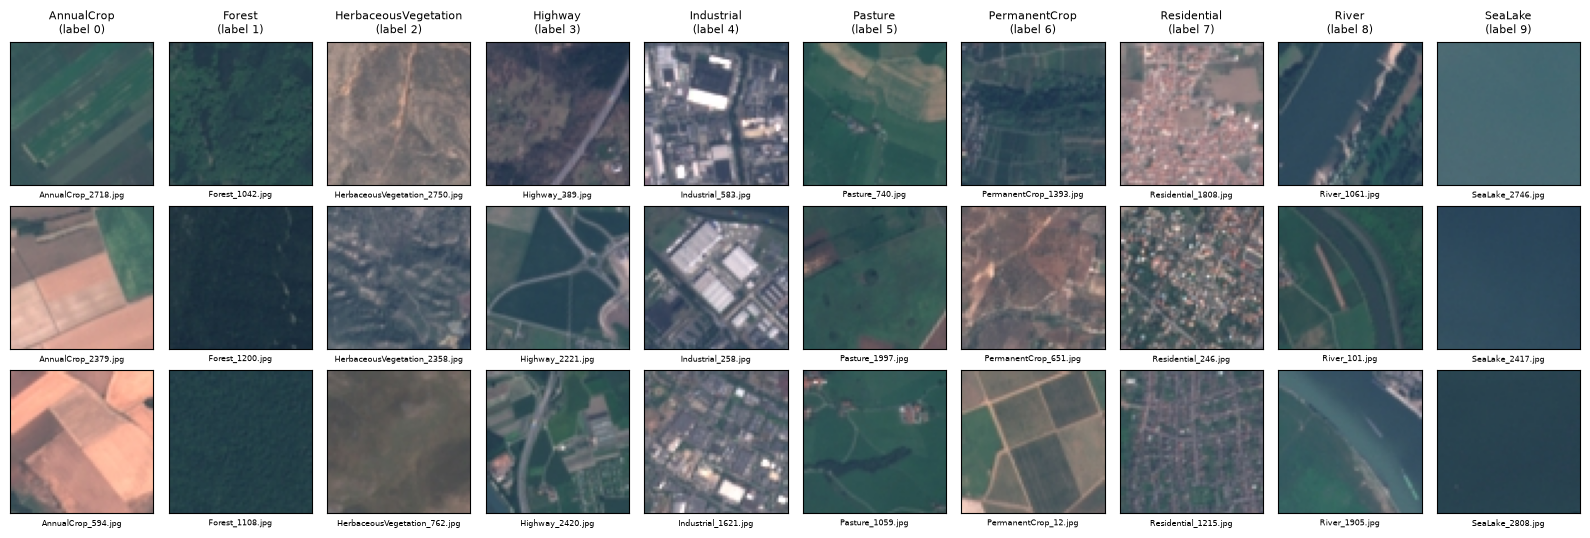

In [5]:
# 5. Proof that the data loads: 3 random images per class with their labels
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, len(CLASSES), figsize=(16, 5.4))
for c, cls in enumerate(CLASSES):
    paths = rng.choice(df.loc[df['label'] == cls, 'path'].to_numpy(), 3, replace=False)
    for r, p in enumerate(paths):
        ax = axes[r, c]
        ax.imshow(Image.open(p)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(os.path.basename(p), fontsize=6)
        if r == 0: ax.set_title(f'{cls}\n(label {c})', fontsize=8)
plt.tight_layout(); plt.savefig('figures/sample_grid.png', dpi=200); plt.show()

In [6]:
# 6. Annotation verification
# Each image's label is the name of the folder it sits in, and the file name repeats it
# (e.g. Forest/Forest_12.jpg). Check that the two always agree and that nothing is duplicated.
import hashlib
df['file_prefix'] = df['path'].map(lambda p: os.path.basename(p).rsplit('_', 1)[0])
mismatch = (df['file_prefix'] != df['label']).sum()
print('Images with a label        :', df['label'].notna().sum(), 'of', len(df))
print('Folder/file-name mismatches:', mismatch)
print('Duplicate file paths       :', df['path'].duplicated().sum())
md5 = df['path'].map(lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest())
print('Byte-identical duplicates  :', md5.duplicated().sum())
print('Label ids                  :', dict(enumerate(CLASSES)))

Images with a label        : 27000 of 27000
Folder/file-name mismatches: 0
Duplicate file paths       : 0


Byte-identical duplicates  : 0
Label ids                  : {0: 'AnnualCrop', 1: 'Forest', 2: 'HerbaceousVegetation', 3: 'Highway', 4: 'Industrial', 5: 'Pasture', 6: 'PermanentCrop', 7: 'Residential', 8: 'River', 9: 'SeaLake'}


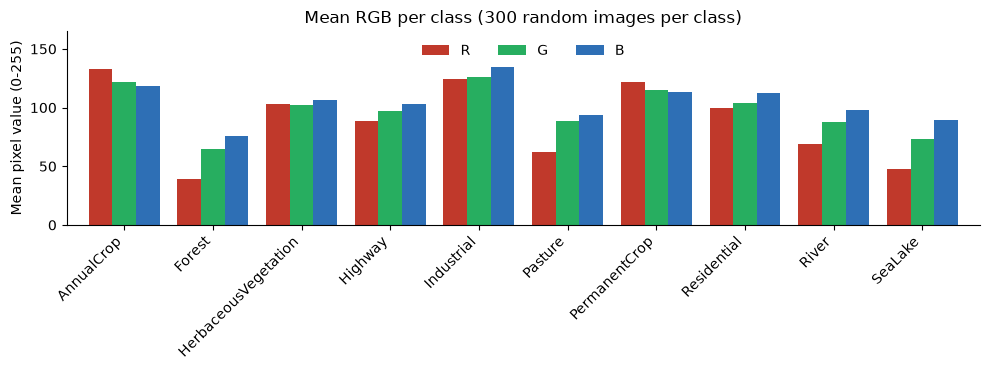

,R,G,B
label,,,
AnnualCrop,133.000000,121.599998,118.500000
Forest,39.200001,64.500000,76.199997
HerbaceousVegetation,102.900002,101.900002,106.599998
Highway,88.199997,96.800003,103.300003
Industrial,124.300003,126.199997,134.899994
Pasture,62.200001,88.699997,93.800003
PermanentCrop,122.099998,115.300003,113.300003
Residential,99.699997,103.599998,112.800003
River,69.000000,87.800003,97.599998


In [7]:
# 7. Mean RGB colour per class (shows the classes differ in simple colour statistics,
#    which is what the colour-histogram baseline will rely on)
sub = df.groupby('label').sample(300, random_state=0)
means = sub.groupby('label')['path'].apply(lambda ps: np.mean([np.asarray(Image.open(p), dtype=np.float32).mean((0, 1)) for p in ps], axis=0))
rgb = pd.DataFrame(means.tolist(), index=means.index, columns=['R', 'G', 'B']).reindex(CLASSES).round(1)
ax = rgb.plot.bar(figsize=(10, 3.8), color=['#c0392b', '#27ae60', '#2e6fb5'], width=0.8)
ax.set_ylabel('Mean pixel value (0-255)'); ax.set_xlabel(''); ax.set_ylim(0, 165)
ax.legend(ncol=3, loc='upper center', frameon=False); ax.set_title('Mean RGB per class (300 random images per class)')
ax.tick_params(axis='x', rotation=45)
for t in ax.get_xticklabels(): t.set_ha('right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('figures/mean_rgb.png', dpi=200); plt.show()
rgb